In [1]:

import pandas as pd
import numpy as np

# Load original sales data
sales = pd.read_csv("../data/raw/sales.csv")

weekly_cols = [str(i) for i in range(12)]

# Convert weekly sales columns to numeric
sales[weekly_cols] = sales[weekly_cols].apply(
    pd.to_numeric, errors="coerce"
)

# 1. Dataset overview
print("DATASET OVERVIEW")
print("----------------")
print("Total product-shop records:", len(sales))
print("Unique products:", sales["external_code"].nunique())
print("Unique retail shops:", sales["retail"].nunique())
print("Unique seasons:", sales["season"].nunique())
print("Unique categories:", sales["category"].nunique())

# 2. Weekly demand statistics
print("\nWEEKLY SALES STATISTICS")
print("-----------------------")

weekly_summary = pd.DataFrame({
    "Mean Sales": sales[weekly_cols].mean(),
    "Median Sales": sales[weekly_cols].median(),
    "Total Sales": sales[weekly_cols].sum(),
    "Zero Sales (%)": (sales[weekly_cols] == 0).mean() * 100
})

display(weekly_summary.round(2))

# 3. First 2 weeks vs next 10 weeks
sales["first_2_weeks"] = sales[["0", "1"]].sum(axis=1)
sales["next_10_weeks"] = sales[
    [str(i) for i in range(2, 12)]
].sum(axis=1)

print("\nDEMAND COMPARISON")
print("-----------------")

print("Average first 2 weeks demand:",
      round(sales["first_2_weeks"].mean(), 2))

print("Average next 10 weeks demand:",
      round(sales["next_10_weeks"].mean(), 2))

print("Average total 12-week demand:",
      round(sales[weekly_cols].sum(axis=1).mean(), 2))

print("\nPercentage of records with zero total demand:",
      round((sales[weekly_cols].sum(axis=1) == 0).mean() * 100, 2), "%")

# 4. Demand distribution
print("\nDEMAND DISTRIBUTION")
print("-------------------")
display(
    sales[["first_2_weeks", "next_10_weeks"]].describe().round(2)
)

# 5. Check missing values
print("\nMISSING VALUES")
print("--------------")
print(sales[weekly_cols].isnull().sum())


DATASET OVERVIEW
----------------
Total product-shop records: 106850
Unique products: 5355
Unique retail shops: 110
Unique seasons: 6
Unique categories: 27

WEEKLY SALES STATISTICS
-----------------------


,Mean Sales,Median Sales,Total Sales,Zero Sales (%)
0,1.83,1.0,195041.0,0.25
1,1.50,1.0,160322.0,26.83
2,1.45,1.0,154722.0,28.71
3,1.46,1.0,155612.0,29.18
4,1.42,1.0,152136.0,29.76
5,1.41,1.0,150649.0,31.11
6,1.34,1.0,143584.0,35.18
7,1.20,1.0,128270.0,40.35
8,1.05,1.0,112269.0,46.56
9,0.90,0.0,95645.0,52.79



DEMAND COMPARISON
-----------------
Average first 2 weeks demand: 3.33
Average next 10 weeks demand: 11.64
Average total 12-week demand: 14.97

Percentage of records with zero total demand: 0.0 %

DEMAND DISTRIBUTION
-------------------


,first_2_weeks,next_10_weeks
count,106850.00,106850.00
mean,3.33,11.64
std,2.27,9.81
min,0.00,0.00
25%,2.00,6.00
50%,3.00,9.00
75%,4.00,13.00
max,52.00,249.00



MISSING VALUES
--------------
0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
dtype: int64


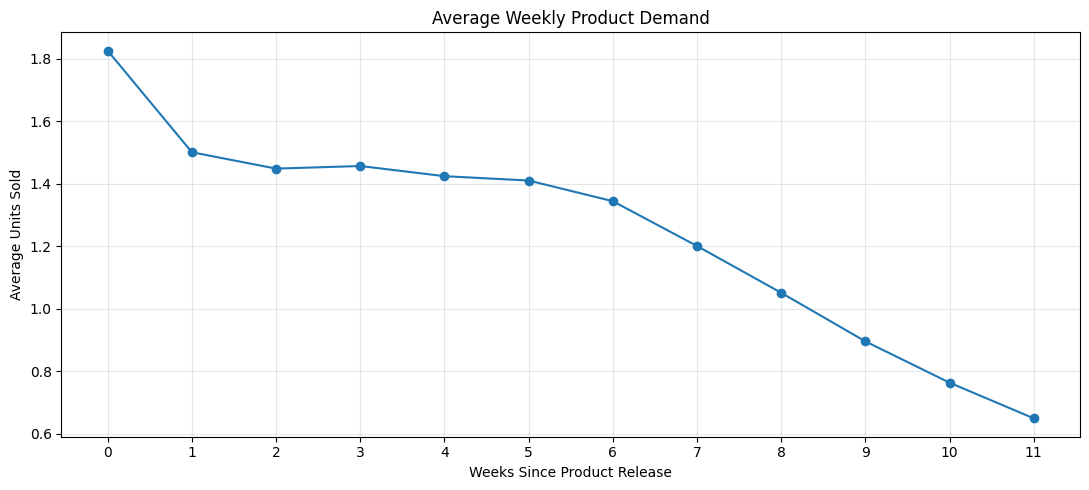

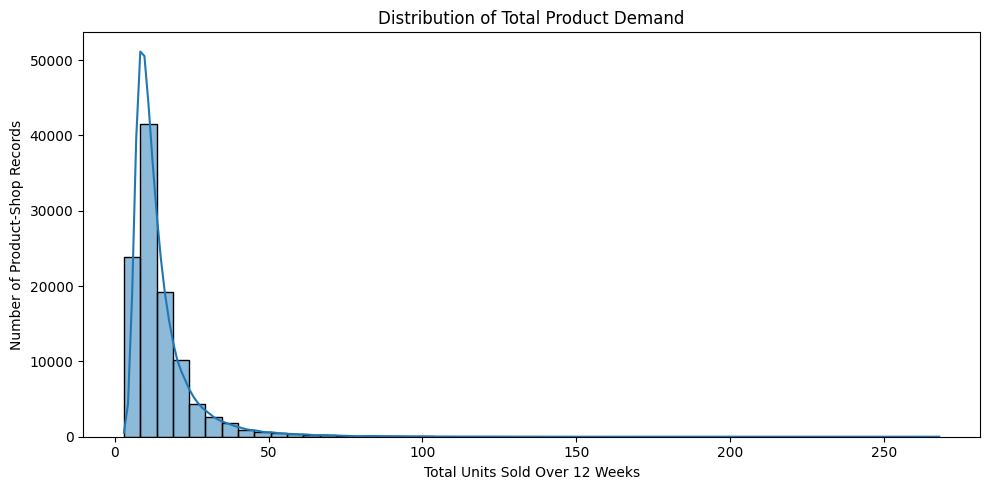

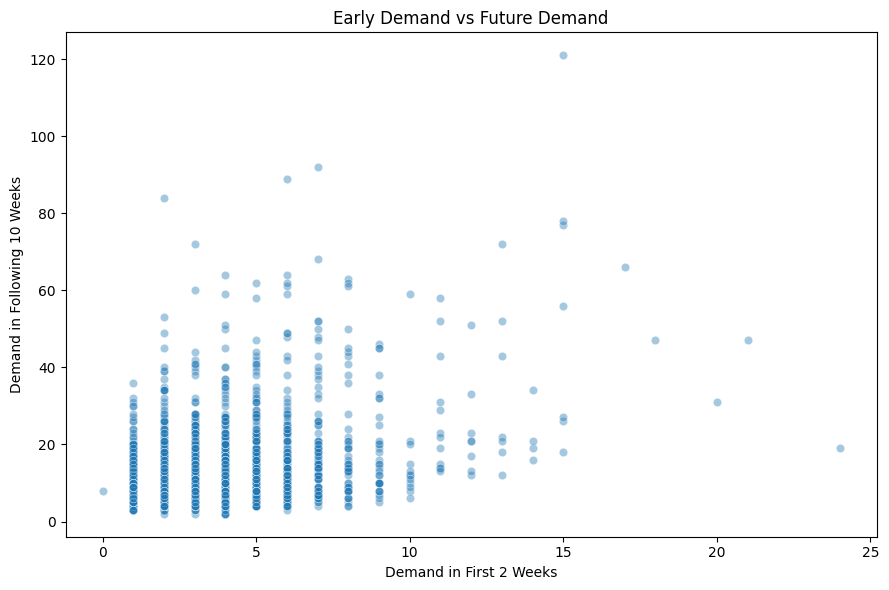

In [2]:

import matplotlib.pyplot as plt
import seaborn as sns

# Weekly average sales
weekly_means = sales[weekly_cols].mean()

plt.figure(figsize=(11, 5))
plt.plot(
    range(12),
    weekly_means.values,
    marker="o"
)
plt.title("Average Weekly Product Demand")
plt.xlabel("Weeks Since Product Release")
plt.ylabel("Average Units Sold")
plt.xticks(range(12))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Distribution of total demand over 12 weeks
sales["total_demand"] = sales[weekly_cols].sum(axis=1)

plt.figure(figsize=(10, 5))
sns.histplot(
    sales["total_demand"],
    bins=50,
    kde=True
)
plt.title("Distribution of Total Product Demand")
plt.xlabel("Total Units Sold Over 12 Weeks")
plt.ylabel("Number of Product-Shop Records")
plt.tight_layout()
plt.show()

# First 2 weeks against next 10 weeks
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=sales.sample(
        min(3000, len(sales)),
        random_state=42
    ),
    x="first_2_weeks",
    y="next_10_weeks",
    alpha=0.4
)
plt.title("Early Demand vs Future Demand")
plt.xlabel("Demand in First 2 Weeks")
plt.ylabel("Demand in Following 10 Weeks")
plt.tight_layout()
plt.show()
